# Monte Carlo Study of the Quartic Anharmonic Oscillator

## Continuum Euclidean Action
Adding a quartic anharmonic potential $V_{\text{anh}}(x) = b x^4$ (with $b > 0$ for vacuum stability and positive recurrence) to the 1D Simple Harmonic Oscillator gives the Euclidean Lagrangian and action:

$$L_E = \frac{1}{2}m\dot{x}^2 + \frac{1}{2}m\omega^2 x^2 + b x^4$$

$$S[x(\tau)] = \int_{\tau_a}^{\tau_b} d\tau \left( \frac{1}{2}m\dot{x}^2 + \frac{1}{2}m\omega^2 x^2 + b x^4 \right)$$

*(Dimensional check: Since $[b x^4] = \text{Energy} = M L^2 T^{-2}$, the coupling constant $b$ has dimensions $[b] = \text{Energy} \cdot L^{-4} = M L^{-2} T^{-2}$.)*


## Lattice Discretization & Non-Dimensionalization
Chopping the Euclidean time interval $\tau_b - \tau_a = N\varepsilon$ into $N$ slices of width $\varepsilon$. We apply the **midpoint prescription** to the harmonic potential $\left(\frac{x_{j+1} + x_j}{2}\right)^2$ and the **endpoint prescription** $\varepsilon b \sum_{j=1}^{N-1} x_j^4$ to the quartic term to avoid nonlinear nearest-neighbor cross-terms like $d_{j+1}^3 d_j$ and $d_{j+1}^2 d_j^2$. With fixed boundary conditions $x_0 = x_N = 0$, the discretized action is:

$$\frac{S}{\hbar} = \frac{m\varepsilon}{2\hbar} \sum_{j=0}^{N-1} \left[ \left(\frac{x_{j+1} - x_j}{\varepsilon}\right)^2 + \omega^2 \left(\frac{x_{j+1} + x_j}{2}\right)^2 \right] + \frac{\varepsilon b}{\hbar} \sum_{j=1}^{N-1} x_j^4$$

* **Step 1 — Introducing Dimensionless Coordinate $d_j$:**
  Using $x_j = d_j \sqrt{\frac{\varepsilon\hbar}{m}}$ and $\kappa = \frac{1}{4}\varepsilon^2\omega^2$:

$$\frac{S}{\hbar} = \frac{1}{2} \sum_{j=0}^{N-1} \Big[ (d_{j+1} - d_j)^2 + \kappa (d_{j+1} + d_j)^2 \Big] + \beta \sum_{j=1}^{N-1} d_j^4$$

  where the dimensionless quartic parameter $\beta$ is:

$$\beta = \frac{b \hbar \varepsilon^3}{m^2}, \qquad [\beta] = \left(M L^{-2} T^{-2}\right)\left(M L^2 T^{-1}\right)\left(M^{-2}\right)\left(T^3\right) = M^0 L^0 T^0 = 1$$

* **Step 2 — Rescaling to Final Lattice Coordinate $u_j$:**
  Expanding the quadratic sum with $d_0 = d_N = 0$ and substituting $u_j = d_j \sqrt{1 + \kappa}$ and $g = \frac{1 - \kappa}{1 + \kappa}$ yields the final dimensionless lattice action:

$$\frac{S[\mathbf{u}]}{\hbar} = \sum_{j=1}^{N-1} u_j^2 - g \sum_{j=0}^{N-1} u_j u_{j+1} + \lambda \sum_{j=1}^{N-1} u_j^4$$

  where the dimensionless lattice quartic coupling $\lambda$ is:

$$\lambda = \frac{\beta}{(1 + \kappa)^2} = \frac{b \hbar \varepsilon^3}{m^2 (1 + \kappa)^2}$$


## Local Action Change ($\delta S_{\text{anh}} / \hbar$) for a Single-Slice Update
Collecting only the terms in $S[\mathbf{u}]/\hbar$ that depend on a single interior slice $u_j$ gives the local action:

$$\frac{S_j}{\hbar} = u_j^2 - g\, u_j (u_{j+1} + u_{j-1}) + \lambda u_j^4$$

When proposing a local Metropolis update $u_j \to \tilde{u}_j = u_j + \delta$ (holding all other slices fixed):

$$\frac{\tilde{S}_j}{\hbar} = (u_j + \delta)^2 - g(u_j + \delta)(u_{j+1} + u_{j-1}) + \lambda (u_j + \delta)^4$$

Expanding $(u_j + \delta)^2 = u_j^2 + 2u_j\delta + \delta^2$ and $(u_j + \delta)^4 = u_j^4 + 4u_j^3\delta + 6u_j^2\delta^2 + 4u_j\delta^3 + \delta^4$, and subtracting $S_j/\hbar$ gives the exact local action difference:

$$\frac{\delta S_{\text{anh}}}{\hbar} = \frac{\tilde{S}_j - S_j}{\hbar} = \Big[ 2u_j - g(u_{j+1} + u_{j-1}) + 4\lambda u_j^3 \Big]\delta + \Big[ 1 + 6\lambda u_j^2 \Big]\delta^2 + 4\lambda u_j \delta^3 + \lambda \delta^4$$

*(Equivalently in code: `dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1])) + lam * ((u[j] + d)**4 - u[j]**4)`.)*


## Quantum Virial Theorem for the Ground State Energy $E_0$
For the anharmonic potential $V(x) = \frac{1}{2}m\omega^2 x^2 + b x^4$, the expectation value of the kinetic energy via the Quantum Virial Theorem is:

$$\langle T \rangle = \frac{1}{2} \left\langle x \frac{dV}{dx} \right\rangle = \frac{1}{2} \Big\langle x \left(m\omega^2 x + 4 b x^3\right) \Big\rangle = \frac{1}{2}m\omega^2 \langle x^2 \rangle + 2 b \langle x^4 \rangle$$

Adding the potential energy $\langle V \rangle = \frac{1}{2}m\omega^2 \langle x^2 \rangle + b \langle x^4 \rangle$ gives the total ground state energy:

$$E_0 = \langle T \rangle + \langle V \rangle = m\omega^2 \langle x^2 \rangle + 3 b \langle x^4 \rangle$$

Converting $x_j$ back into the dimensionless lattice coordinate $u_j$ via $x_j = u_j \sqrt{\frac{\hbar\varepsilon}{m(1+\kappa)}}$:

$$E_0 = m\omega^2 \left[ \frac{\hbar\varepsilon}{m(1+\kappa)} \right] \langle u_j^2 \rangle + 3 b \left[ \frac{\hbar\varepsilon}{m(1+\kappa)} \right]^2 \langle u_j^4 \rangle$$

Dividing both sides by $\hbar\omega$ and substituting $\lambda = \frac{b \hbar \varepsilon^3}{m^2 (1 + \kappa)^2}$ yields the dimensionless Virial energy estimator:

$$\frac{E_0}{\hbar\omega} = \frac{\omega\varepsilon}{1 + \kappa} \langle u_j^2 \rangle + \frac{3\lambda}{\omega\varepsilon} \langle u_j^4 \rangle$$


## Analytic Perturbation Theory Comparison (1st & 2nd Order)

To benchmark the non-perturbative Monte Carlo results against Rayleigh-Schrödinger perturbation theory for $V_{\text{anh}}(x) = b x^4$, we expand the energy of the $n$-th state up to second order in $b$:

$$E_n = E_n^{(0)} + E_n^{(1)} + E_n^{(2)} + \mathcal{O}(b^3)$$

where the unperturbed energy is $E_n^{(0)} = \left(n + \frac{1}{2}\right)\hbar\omega$. Using the dimensionless lattice coupling $\lambda = \frac{b \hbar \varepsilon^3}{m^2 (1 + \kappa)^2}$, we substitute $b = \frac{m^2 \lambda (1 + \kappa)^2}{\hbar \varepsilon^3}$ to express each correction purely in terms of our lattice parameters:

* **1st-Order Energy Correction:**
  Starting from $E_n^{(1)} = b \left(\frac{\hbar}{2m\omega}\right)^2 (6n^2 + 6n + 3)$ at the ground state $n = 0$, dividing by $\hbar\omega$ gives $\frac{E_0^{(1)}}{\hbar\omega} = \frac{3 b \hbar}{4 m^2 \omega^3}$. Substituting $b$ cancels all factors of $m^2$ and $\hbar$:

$$\frac{E_0^{(1)}}{\hbar\omega} = \frac{3\hbar}{4 m^2 \omega^3} \left[ \frac{m^2 \lambda (1 + \kappa)^2}{\hbar \varepsilon^3} \right] = \frac{3}{4} \frac{\lambda (1 + \kappa)^2}{(\omega\varepsilon)^3}$$

* **2nd-Order Energy Correction:**
  Using the exact second-order Rayleigh-Schrödinger perturbation formula with $K = m\omega^2$:

$$E_n^{(2)} = -\frac{b^2}{8 (m\omega^2)^4} (\hbar\omega)^3 \left(34n^3 + 51n^2 + 59n + 21\right)$$

  *(Note: Factoring $8$ out of the numerator polynomial $24 + 144 = 168 = 8 \times 21$ at $n=0$ against $64$ in the denominator yields $\frac{8}{64} = \frac{1}{8}$.)* Evaluating at $n = 0$ and dividing by $\hbar\omega$ gives $\frac{E_0^{(2)}}{\hbar\omega} = -\frac{21 b^2 \hbar^2}{8 m^4 \omega^6}$. Substituting $b^2$ gives:

$$\frac{E_0^{(2)}}{\hbar\omega} = -\frac{21 \hbar^2}{8 m^4 \omega^6} \left[ \frac{m^4 \lambda^2 (1 + \kappa)^4}{\hbar^2 \varepsilon^6} \right] = -\frac{21}{8} \frac{\lambda^2 (1 + \kappa)^4}{(\omega\varepsilon)^6}$$

* **Combined Ground State Perturbation Series:**
  Defining the dimensionless continuum coupling parameter $\alpha = \frac{\lambda (1 + \kappa)^2}{(\omega\varepsilon)^3}$, the full perturbative expansion up to second order is:

$$\frac{E_0}{\hbar\omega} = \frac{1}{2} + \frac{3}{4} \frac{\lambda (1 + \kappa)^2}{(\omega\varepsilon)^3} - \frac{21}{8} \frac{\lambda^2 (1 + \kappa)^4}{(\omega\varepsilon)^6} = \frac{1}{2} + \frac{3}{4}\alpha - \frac{21}{8}\alpha^2$$

In [2]:
from numba import njit

## Autocorrelation Plot

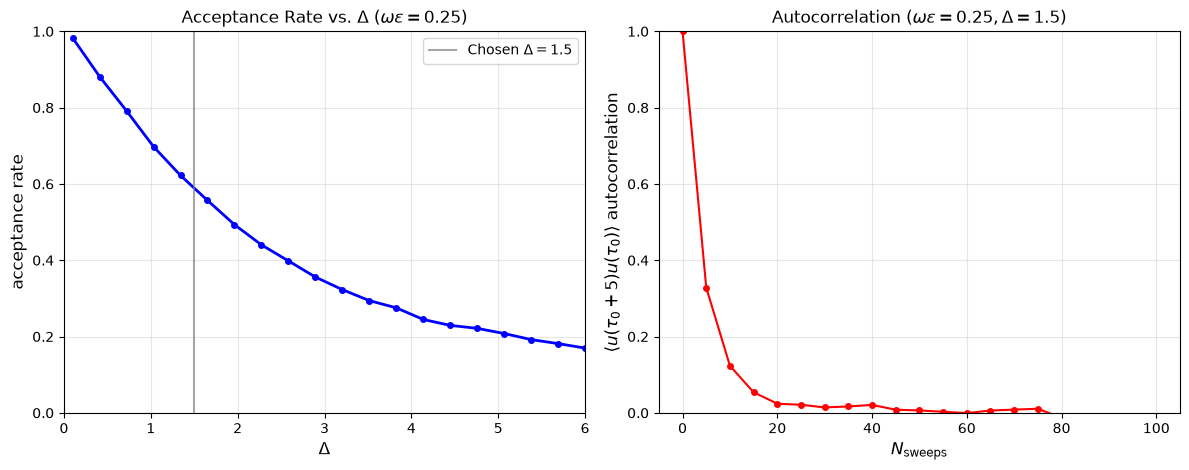

In [3]:
# Autocorrelation and acceptance rate analysis for the Anharmonic Oscillator lattice 

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)


# =====================================================================
# 1. Anharmonic Oscillator Lattice Parameters 
# =====================================================================
omega_eps = 0.25
kappa = 0.25 * (omega_eps ** 2)
g = (1.0 - kappa) / (1.0 + kappa)
Nt = 1000  # Path has slices j = 0, 1, ..., Nt with u_0 = u_Nt = 0
lam = 0.05  # Anharmonic coupling constant

# =====================================================================
# 2. Sequential Sweep Function
# =====================================================================
@njit # decorator to speed up the function using Numba's JIT compilation
def sweep_sequential_anh(u, g, lam, Delta, rng): # Delta is the width of the uniform random displacement for Metropolis updates
    Nt = len(u) - 1
    accepted = 0
    for j in range(1, Nt):
        d = rng.uniform(-Delta, Delta)
        u_new = u[j] + d
        dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1])) + lam * (u_new**4 - u[j]**4)
        if dS <= 0.0 or rng.random() < np.exp(-dS):
            u[j] = u_new
            accepted += 1
    return accepted / (Nt - 1)


def measure_correlator(u, tau, i_start=200, i_end=800): # i_start and i_end define the middle region of the path to avoid boundary effects
    """Measures <u(tau0 + tau) u(tau0)> averaged over the middle region."""
    return np.mean(u[i_start : i_end] * u[i_start + tau : i_end + tau])

def compute_autocorr(series, max_lag=100):
    """Computes normalized autocorrelation rho(tau) for lags 0..max_lag."""
    fluct = series - np.mean(series)
    R0 = np.mean(fluct**2)
    N = len(series)
    rho = np.ones(max_lag + 1)
    for h in range(1, max_lag + 1):
        rho[h] = np.sum(fluct[:-h] * fluct[h:]) / ((N - h) *  R0)
    return rho

# =====================================================================
# 3. Left Plot: Acceptance Rate vs. Delta
# =====================================================================
delta_grid = np.linspace(0.1, 6.0, 20)
acc_rates = []

for d_val in delta_grid:
    u_temp = np.zeros(Nt + 1)
    # Quick thermalization + measurement of acceptance rate
    for _ in range(30):
        sweep_sequential_anh(u_temp, g, lam, d_val, rng)
    acc = np.mean([sweep_sequential_anh(u_temp, g, lam, d_val, rng) for _ in range(20)])
    acc_rates.append(acc)

# =====================================================================
# 4. Right Plot: Autocorrelation vs. N_sweeps
# =====================================================================
Delta = 1.5
n_therm = 300
n_track = 25000  # Consecutive sweeps to measure autocorrelation up to lag 25000 or number of paths 25000.

u_seq = np.zeros(Nt + 1)
for _ in range(n_therm):
    sweep_sequential_anh(u_seq, g, lam, Delta, rng) # thermalization sweeps
obs_seq = np.array([
    (sweep_sequential_anh(u_seq, g, lam, Delta, rng), measure_correlator(u_seq, tau=5))[1] # find a paths in equilibrium, then measure the correlator at tau=5. 
    for _ in range(n_track) # (func1(), func2())[1] syntax is used. The [1] returns the func2() only
]) # Repeat n_track times or for 25000 paths to get a long time series of the correlator at lag tau=5.


sweeps = np.arange(0, 101, 5)
rho_seq = compute_autocorr(obs_seq, max_lag=100)[sweeps] # NumPy Fancy Indexing (array indexing). Extracts data at different sweeps 

# =====================================================================
# 5. Plot Reproduction 
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: Acceptance Rate vs Delta
ax1.plot(delta_grid, acc_rates, 'b-o', markersize=4, lw=2)
ax1.axvline(1.5, color='gray', ls='-', alpha=0.7, label=r'Chosen $\Delta = 1.5$')
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 1.0)
ax1.set_xlabel(r'$\Delta$', fontsize=12)
ax1.set_ylabel('acceptance rate', fontsize=12)
ax1.set_title(r'Acceptance Rate vs. $\Delta$ ($\omega\varepsilon = 0.25$)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right Panel: Autocorrelation vs N_sweeps
ax2.plot(sweeps, rho_seq, '-o', markersize=4, color='r')
ax2.set_ylim(0, 1.0)
ax2.set_xlabel(r'$N_{\mathrm{sweeps}}$', fontsize=12)
ax2.set_ylabel(r'$\langle u(\tau_0+5)u(\tau_0)\rangle$ autocorrelation', fontsize=12)
ax2.set_title(r'Autocorrelation ($\omega\varepsilon = 0.25, \Delta = 1.5$)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Correlation Function

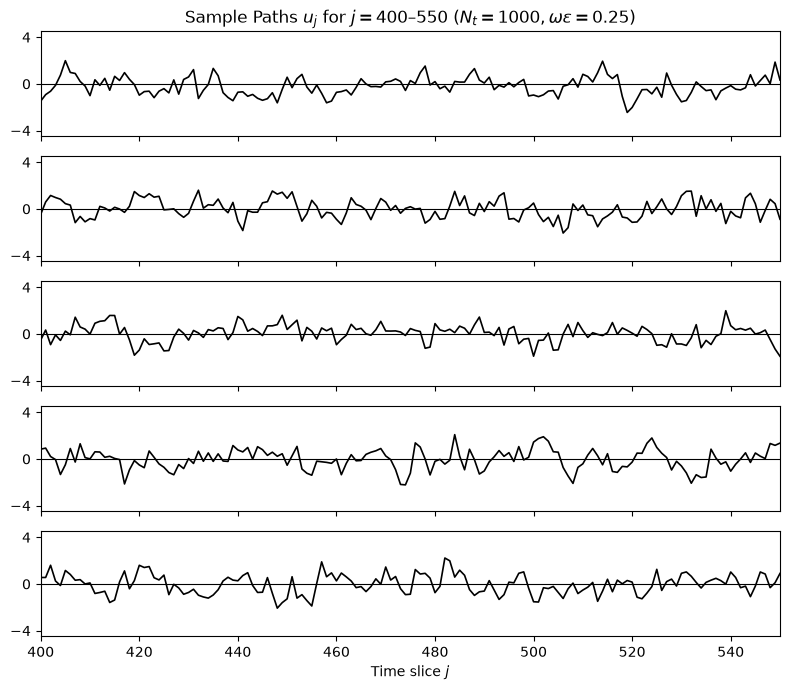

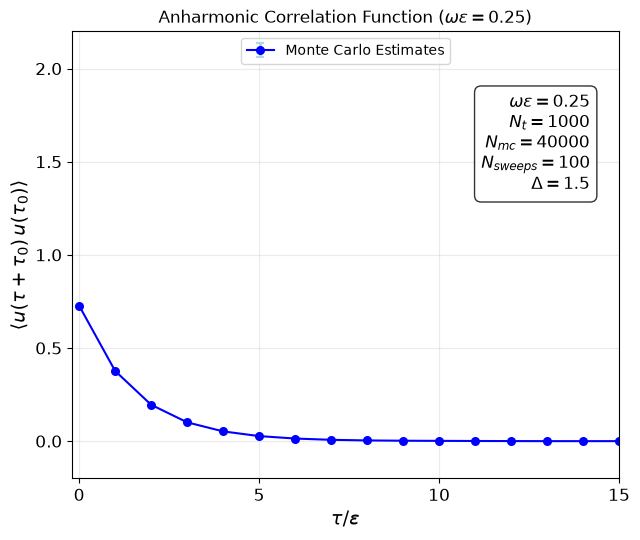

In [4]:
# =====================================================================
# Reproducing Sample Paths and Correlation Function
# =====================================================================
Delta = 1.5 # Width of uniform random displacement for Metropolis updates
N_therm = 500
N_sweeps = 100    # Sweeps skipped between saved measurements
N_mc = 40000       # Number of decorrelated path measurements
max_tau = 15     # Evaluate <u(tau0 + tau) u(tau0)> for tau/eps = 0..15

# = np.ones(Nt + 1)  # hot start: u_j = 1 for all j
u = np.zeros(Nt + 1)  # cold start: u_j = 0 for all j

# 1. Thermalization Phase
for _ in range(N_therm):
    sweep_sequential_anh(u, g, lam, Delta, rng)

# 2. Measurement Phase
saved_paths = []
corr_samples = np.zeros((N_mc, max_tau + 1)) # Store <u(tau0 + tau) u(tau0)> for each decorrelated path. max_tau + 1 because we include tau=0.
i_start, i_end = 200, 800  # Bulk interior region away from ends u_0 = u_Nt = 0


for m in range(N_mc):
    # Skip N_sweeps between measurements to decorrelate paths
    for _ in range(N_sweeps):
        sweep_sequential_anh(u, g, lam, Delta, rng)
        
    # Save first 5 decorrelated paths for Fig. 9 (slices j = 400..550)
    if m < 5:
        saved_paths.append(u[400:551].copy())
        
    # Measure <u(tau0 + tau) u(tau0)>. Means averaging across the physical length of a single path. See mini example below. 
    u_base = u[i_start:i_end]
    for tau in range(max_tau + 1):
        corr_samples[m, tau] = np.mean(u_base * u[i_start + tau : i_end + tau])

# Compute Monte Carlo mean and standard error for each tau. It is like taking the ensemble average of the correlation function across all N_mc paths.
mc_corr_mean = np.mean(corr_samples, axis=0) # axis 0 means operating over rows, which gives result for each column (tau). From 400 paths to 1 path for each as a function of time slice tau.
mc_corr_err = np.std(corr_samples, axis=0, ddof=1) / np.sqrt(N_mc) # ddof=1 gives unbiased sample standard deviation


# =====================================================================
# Plot Sample Quantum Paths for j = 400 - 550
# =====================================================================
fig, axes = plt.subplots(5, 1, figsize=(8, 7), sharex=True)
j_slice = np.arange(400, 551)

for idx, ax in enumerate(axes): # enumerate gives both the index and the element from saved_paths
    ax.plot(j_slice, saved_paths[idx], 'k-', lw=1.2)
    ax.axhline(0.0, color='black', lw=0.8)
    ax.set_ylim(-4.5, 4.5)
    ax.set_yticks([-4, 0, 4])
    ax.set_xlim(400, 550)

axes[0].set_title(r'Sample Paths $u_j$ for $j = 400\text{–}550$ ($N_t = 1000, \omega\varepsilon = 0.25$)')
axes[-1].set_xlabel('Time slice $j$')
plt.tight_layout()
plt.show()

# =====================================================================
# Plot Fig. 10: Two-Point Correlation Function <u(tau0 + tau) u(tau0)>
# =====================================================================
tau_vals = np.arange(0, max_tau + 1) # tau =  0, 1, 2,.. ,15
plt.figure(figsize=(6.5, 5.5))
plt.errorbar(tau_vals, mc_corr_mean, yerr=mc_corr_err, fmt='o-', markersize=5,
             capsize=3, label='Monte Carlo Estimates', color='blue', ecolor='lightblue', elinewidth=2, markeredgewidth=1.5)

plt.xlim(-0.2, 15)
plt.ylim(-0.2, 2.2)
plt.xticks([0, 5, 10, 15], fontsize=12)
plt.yticks([0, 0.5, 1, 1.5, 2], fontsize=12)
plt.xlabel(r'$\tau / \varepsilon$', fontsize=14)
plt.ylabel(r'$\langle u(\tau + \tau_0)\, u(\tau_0) \rangle$', fontsize=14)
plt.title(r'Anharmonic Correlation Function ($\omega\varepsilon = 0.25$)')

# Add parameter text box matching Fig. 10
info_text = (
    rf"$\omega\varepsilon = {omega_eps}$" + "\n" +
    rf"$N_t = {Nt}$" + "\n" +
    rf"$N_{{mc}} = {N_mc}$" + "\n" +
    rf"$N_{{sweeps}} = {N_sweeps}$" + "\n" +
    rf"$\Delta = {Delta}$"
)
plt.text(14.2, 1.35, info_text, fontsize=12, horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8))

plt.legend(loc='upper center', fontsize=10)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## Ground State Wavefunction and Energy

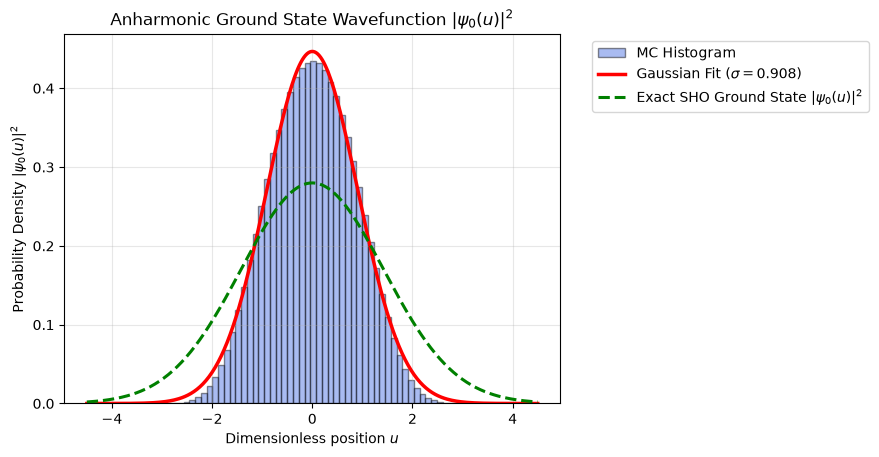

In [5]:
# =====================================================================
# Extracting Ground State Wavefunction |psi_0(u)|^2 
# =====================================================================

from matplotlib.pyplot import plot
from scipy.optimize import curve_fit

max_tau = 15  # Maximum tau for correlation function

# Collect bulk path values u_j across decorrelated sweeps for the wavefunction
u_samples = []
u_wf = np.zeros(Nt + 1)

# Thermalize
for _ in range(N_therm):
    sweep_sequential_anh(u_wf, g, lam, Delta, rng)

# Measure interior u_j values and correlator simultaneously
corr_samples_wf = np.zeros((N_mc, max_tau + 1))


for m in range(N_mc):
    for _ in range(N_sweeps):
        sweep_sequential_anh(u_wf, g, lam, Delta, rng)
        
    u_base = u_wf[i_start:i_end]
    u_samples.append(u_base.copy())  # Store 600 interior slices per snapshot
    
    for tau in range(max_tau + 1):
        corr_samples_wf[m, tau] = np.mean(u_base * u_wf[i_start + tau : i_end + tau])

u_all = np.concatenate(u_samples)  # 40000 * 600 = 24,000,000 position measurements!
mc_corr_mean = np.mean(corr_samples_wf, axis=0) # Compute <u(tau0 + tau) u(tau0)> averaged over all N_mc paths at each tau.


# Ground State Probability Density |psi_0(u)|^2 and Wavefunction psi_0(u)

# 1. Compute the MC histogram from your flattened bulk path slices (u_all)
counts, bin_edges = np.histogram(u_all, bins=60, density=True)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# 2. Define a Gaussian fit function
def gaussian(u, A, sigma):
    return A * np.exp(-u**2 / (2.0 * sigma**2))

# 3. Fit the histogram data using curve_fit
p0 = [1.0, 2.0]  # Initial guesses for amplitude and standard deviation (sigma)
popt, pcov = curve_fit(gaussian, bin_centers, counts, p0=p0)
A_fit, sigma_fit = popt

# 4. Generate smooth points for the fitted curve
u_grid = np.linspace(-4.5, 4.5, 300)
fit_curve = gaussian(u_grid, A_fit, sigma_fit)

# 5. Plot the histogram and the fit
plt.hist(u_all, bins=60, density=True, alpha=0.45, color='royalblue', edgecolor='black', label='MC Histogram')
plt.plot(u_grid, fit_curve, 'r-', lw=2.5, label=rf'Gaussian Fit ($ \sigma = {sigma_fit:.3f}$)')
sigma2_exact = (1.0 + kappa) / (4.0 * 0.5 * omega_eps)  
psi0_sq_exact = (1.0 / np.sqrt(2.0 * np.pi * sigma2_exact)) * np.exp(-u_grid**2 / (2.0 * sigma2_exact))
plt.plot(u_grid, psi0_sq_exact, 'g--', lw=2.2, label=r'Exact SHO Ground State $|\psi_0(u)|^2$')
plt.xlabel(r'Dimensionless position $u$')
plt.ylabel(r'Probability Density $|\psi_0(u)|^2$')
plt.title(r'Anharmonic Ground State Wavefunction $|\psi_0(u)|^2$')
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)

=== Coupling lambda = 0.05 (alpha = 3.3008) ===
 -> MC Virial E_0 / (hbar*omega):       1.0063 +/- 0.0001
 -> MC Propagator E_0 / (hbar*omega):   1.3146
 -> 1st-Order Perturbation Theory:      2.9756
 -> 2nd-Order Perturbation Theory:      -25.6242



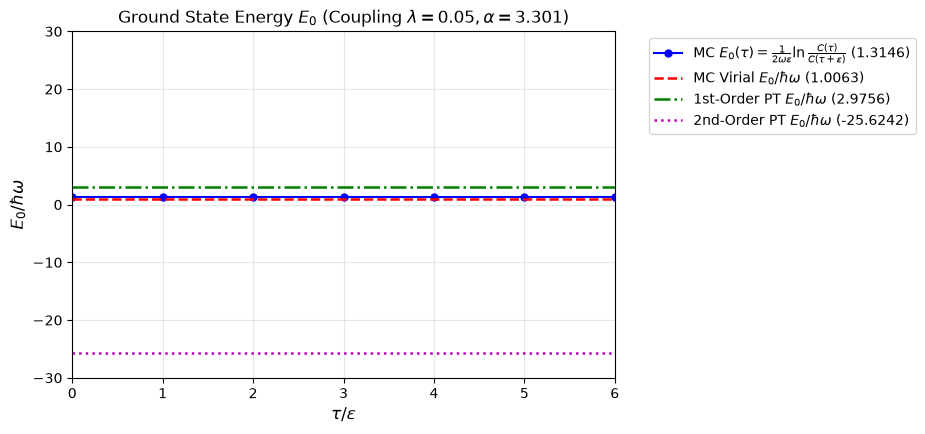

=== Coupling lambda = 0.005 (alpha = 0.3301) ===
 -> MC Virial E_0 / (hbar*omega):       0.6388 +/- 0.0001
 -> MC Propagator E_0 / (hbar*omega):   0.7426
 -> 1st-Order Perturbation Theory:      0.7476
 -> 2nd-Order Perturbation Theory:      0.4616



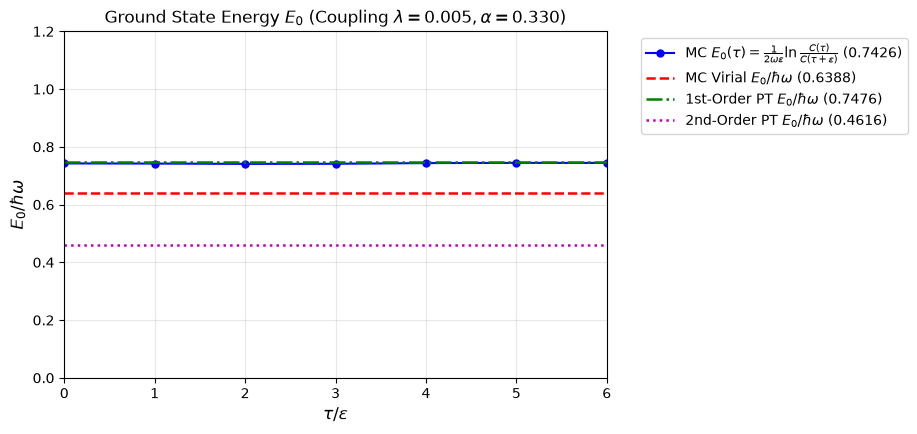

=== Coupling lambda = 0.0005 (alpha = 0.0330) ===
 -> MC Virial E_0 / (hbar*omega):       0.5216 +/- 0.0002
 -> MC Propagator E_0 / (hbar*omega):   0.5450
 -> 1st-Order Perturbation Theory:      0.5248
 -> 2nd-Order Perturbation Theory:      0.5219



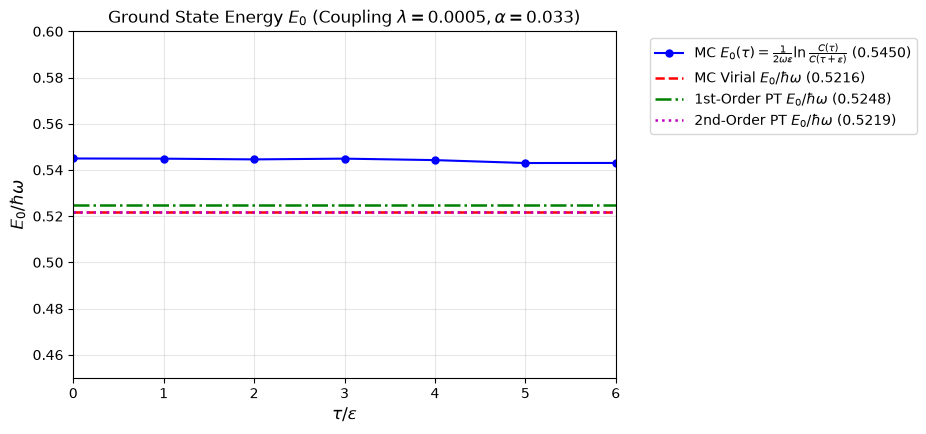

In [7]:
max_tau = 7  # Maximum tau for correlation function
lam_list = [0.05, 0.005, 0.0005]  # Anharmonic coupling constants

for lam in lam_list:
    # Collect bulk path values u_j across decorrelated sweeps for the wavefunction
    u_samples = []
    u_wf = np.zeros(Nt + 1)

    # Thermalize
    for _ in range(N_therm):
        sweep_sequential_anh(u_wf, g, lam, Delta, rng)

    # Measure interior u_j values and correlator simultaneously
    corr_samples_wf = np.zeros((N_mc, max_tau + 1))

    for m in range(N_mc):
        for _ in range(N_sweeps):
            sweep_sequential_anh(u_wf, g, lam, Delta, rng)
            
        u_base = u_wf[i_start:i_end]
        u_samples.append(u_base.copy())  # Store 600 interior slices per snapshot
        
        for tau in range(max_tau + 1):
            corr_samples_wf[m, tau] = np.mean(u_base * u_wf[i_start + tau : i_end + tau])

    u_all = np.concatenate(u_samples)
    mc_corr_mean = np.mean(corr_samples_wf, axis=0)

    # =====================================================================
    # Compute Ground State Energy E_0 (in units of hbar * omega)
    # =====================================================================
    # Method A: Anharmonic Virial Theorem E_0 / (hbar * omega)
    u2_mean = np.mean(u_all**2)
    u4_mean = np.mean(u_all**4)

    # Standard error for u^2 across N_mc paths
    u2_err = np.std(np.mean(np.array(u_samples)**2, axis=1), ddof=1) / np.sqrt(N_mc)

    # Anharmonic Virial formula: (omega_eps / (1 + kappa)) * <u^2> + (3 * lam / omega_eps) * <u^4>
    prefactor_u2 = omega_eps / (1.0 + kappa)
    prefactor_u4 = 3.0 * lam / omega_eps

    E0_virial = prefactor_u2 * u2_mean + prefactor_u4 * u4_mean
    E0_virial_err = prefactor_u2 * u2_err  # Dominant statistical error contribution

    # Method B: Effective Energy Gap from Propagator Ratio ln(C(tau) / C(tau+1))
    eff_gap = (1.0 / omega_eps) * np.log(mc_corr_mean[:-1] / mc_corr_mean[1:])
    E0_from_prop = 0.5 * eff_gap[0]  # Using tau=0 -> tau=1 step (highest signal-to-noise)

    # =====================================================================
    # Analytic Perturbation Theory Comparison (1st & 2nd Order)
    # =====================================================================
    alpha = lam * (1.0 + kappa)**2 / (omega_eps**3)

    E0_pert_1st = 0.5 + (3.0 / 4.0) * alpha
    E0_pert_2nd = 0.5 + (3.0 / 4.0) * alpha - (21.0 / 8.0) * (alpha**2)

    print(f"=== Coupling lambda = {lam} (alpha = {alpha:.4f}) ===")
    print(f" -> MC Virial E_0 / (hbar*omega):       {E0_virial:.4f} +/- {E0_virial_err:.4f}")
    print(f" -> MC Propagator E_0 / (hbar*omega):   {E0_from_prop:.4f}")
    print(f" -> 1st-Order Perturbation Theory:      {E0_pert_1st:.4f}")
    print(f" -> 2nd-Order Perturbation Theory:      {E0_pert_2nd:.4f}\n")

    # =====================================================================
    # Plot Effective Ground State Energy vs tau/eps
    # =====================================================================
    plt.figure(figsize=(7, 4.5))
    tau_steps = np.arange(len(eff_gap))
    
    plt.plot(tau_steps, 0.5 * eff_gap, 'bo-', markersize=5, 
             label=rf'MC $E_0(\tau) = \frac{{1}}{{2\omega\varepsilon}}\ln\frac{{C(\tau)}}{{C(\tau+\varepsilon)}}$ ({E0_from_prop:.4f})')
    plt.axhline(E0_virial, color='r', ls='--', lw=1.8, 
                label=rf'MC Virial $E_0 / \hbar\omega$ ({E0_virial:.4f})')
    plt.axhline(E0_pert_1st, color='g', ls='-.', lw=1.8, 
                label=rf'1st-Order PT $E_0 / \hbar\omega$ ({E0_pert_1st:.4f})')
    plt.axhline(E0_pert_2nd, color='m', ls=':', lw=1.8, 
                label=rf'2nd-Order PT $E_0 / \hbar\omega$ ({E0_pert_2nd:.4f})')
    
    plt.xlim(0, 6)
    if lam == 0.05:
        plt.ylim(-30, 30)
    elif lam == 0.005:
        plt.ylim(0.0, 1.2)
    else:
        plt.ylim(0.45, 0.60)
        
    plt.xlabel(r'$\tau / \varepsilon$', fontsize=12)
    plt.ylabel(r'$E_0 / \hbar\omega$', fontsize=12)
    plt.title(rf'Ground State Energy $E_0$ (Coupling $\lambda = {lam}, \alpha = {alpha:.3f}$)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True, alpha=0.3)
    plt.show()